##**A) Data Manipulation**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("telco_data.csv")

# Clean column name
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for column in df.select_dtypes(include=['object']).columns:
    df[column] = df[column].str.strip()

# Convert total charge to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace('', np.nan), errors='coerce')

# Blank TotalCharges for zero-tenure customers means zero charges
df.loc[(df['tenure'] == 0) & (df['TotalCharges'].isnull()), 'TotalCharges'] = 0

print(" data shape ", df.shape)
df.head()

 data shape  (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

# Check dataset dimensions
print("Rows and columns:", df.shape)

# Check column data types
print("\n Data types:")
df.info()

# Check missing values
print("\n Missing values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0]
      if missing_values.any()
      else "No missing values found.")

# Check duplicate records
print("\n Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:",
      df['customerID'].duplicated().sum())

# Check target distribution
print("\n Churn distribution:")
print(df['Churn'].value_counts(dropna=False))

# Check numerical ranges
print("\n Numerical summary:")
display(
    df[['tenure', 'MonthlyCharges', 'TotalCharges']]
    .describe()
)

# Validate customer IDs and target labels
assert df['customerID'].is_unique, "Duplicate customer IDs found!"
assert df['Churn'].isin(['Yes', 'No']).all(), "Invalid churn labels!"

print("\n Basic validation completed.")


Rows and columns: (7043, 21)

 Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16 

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000



 Basic validation completed.


1. Total number of male customers

In [6]:
male_customers = (df['gender'] == 'Male').sum()

print("Total number of male customers:", male_customers)

Total number of male customers: 3555


2. Total number of customers whose Internet Service is DSL

In [7]:
dsl_customers = (df['InternetService'] == 'DSL').sum()

print("Total customers with DSL Internet Service:", dsl_customers)

Total customers with DSL Internet Service: 2421


3. Female senior citizens whose Payment Method is Mailed check

In [8]:
new_customer = df[
    (df['gender'] == 'Female') &
    (df['SeniorCitizen'] == 1) &
    (df['PaymentMethod'] == 'Mailed check')
]

print("Number of customers:", len(new_customer))
new_customer.head()

Number of customers: 50


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
139,0390-DCFDQ,Female,1,Yes,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,70.45,70.45,Yes
176,2656-FMOKZ,Female,1,No,No,15,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.45,1145.70,Yes
267,3197-ARFOY,Female,1,No,No,19,Yes,No,Fiber optic,Yes,...,No,Yes,Yes,Yes,Month-to-month,Yes,Mailed check,105.00,2007.25,No
451,5760-WRAHC,Female,1,No,No,22,Yes,No,DSL,Yes,...,Yes,Yes,No,Yes,Month-to-month,Yes,Mailed check,69.75,1545.40,No
470,4933-IKULF,Female,1,No,No,17,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.65,330.60,No


4. Customers whose tenure is less than 10 months OR Total Charges is less than $500

In [9]:
new_customer = df[
    (df['tenure'] < 10) |
    (df['TotalCharges'] < 500)
]

print("Number of customers:", len(new_customer))
new_customer.head()

Number of customers: 2233


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No


## **B) Data Visualization**
1. Pie chart — Churn distribution

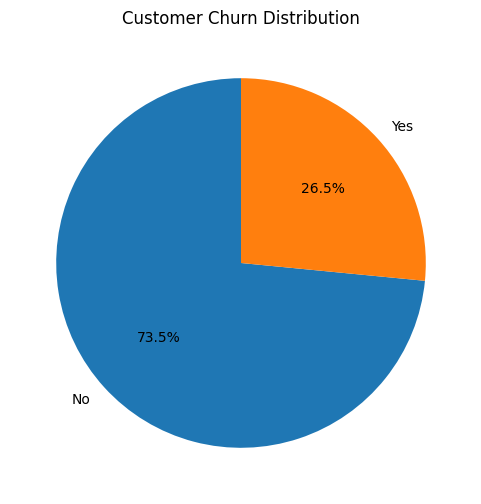

In [10]:
import matplotlib.pyplot as plt

churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Customer Churn Distribution")
plt.show()

Observation

The pie chart shows the proportion of customers who stayed (No) and churned (Yes). The dataset is imbalanced because customers who did not churn are considerably more numerous than customers who churned.

2. Bar plot — Internet Service distribution

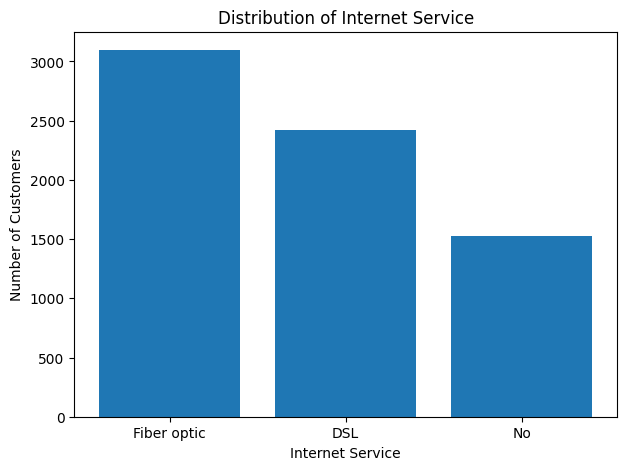

In [11]:
internet_counts = df['InternetService'].value_counts()

plt.figure(figsize=(7,5))

plt.bar(
    internet_counts.index,
    internet_counts.values
)

plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.title("Distribution of Internet Service")

plt.show()

Observation

The bar plot shows the number of customers using DSL, Fiber optic, and No internet service.

## C) **Model Building**

In [12]:
# Check the original churn labels
print("Churn distribution:")
display(df['Churn'].value_counts().to_frame('Customer Count'))

# Check churn percentages
print("\nChurn percentages:")
display(
    (df['Churn'].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame('Percentage')
)

# Confirm target labels are valid
assert df['Churn'].isin(['Yes', 'No']).all()

print("\nTarget validation completed.")


Churn distribution:


,Customer Count
Churn,
No,5174
Yes,1869



Churn percentages:


,Percentage
Churn,
No,73.46
Yes,26.54



Target validation completed.


### import neccesary library

In [13]:
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)


### Split the data

We divide the dataset into three subsets:

- Training set (60%): trains the models.
- Validation set (20%): compares models and selects classification thresholds.
- Test set (20%): evaluates final model performance.

Stratified splitting preserves the approximate churn distribution in each subset. The test set remains separate during model training and selection.

In [14]:
# Separate features and target
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

# Split off the final test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split remaining data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))


Training rows: 4225
Validation rows: 1409
Test rows: 1409


### Data Preprocessing

Numerical and categorical features require different preprocessing steps.

- Numerical features: missing-value imputation using the median, followed by standardization.
- Categorical features: missing-value imputation using the most frequent value, followed by one-hot encoding.

A separate preprocessing pipeline is fitted for each model to keep transformations consistent and prevent information leakage from validation and test data.

In [15]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()


# Create a fresh preprocessing pipeline for each model
def make_preprocessor():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])


### Model building

#### Initial Model Selection

We compare five classifiers:

1. Dummy Classifier — baseline performance.
2. Logistic Regression — interpretable classification model.
3. Random Forest — ensemble of decision trees.
4. HistGradientBoosting — boosting-based classifier.
5. MLP Neural Network — neural network for nonlinear patterns.

We compare accuracy, precision, recall, F1-score and ROC-AUC. F1-score helps balance precision and recall, while recall measures how many actual churners are identified.

In [16]:
# Define the models
models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Boosting': HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        l2_regularization=1.0,
        random_state=42
    ),

    'MLP Neural Network': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        random_state=42
    )
}



### Training and model Compareing using validation data

In [17]:
# Train
results = []
trained_models = {}

for name, classifier in models.items():

    model = Pipeline([
        ('preprocessing', make_preprocessor()),
        ('classifier', classifier)
    ])

    # Apply class weights to the boosting model
    if name == 'Boosting':
        sample_weights = compute_sample_weight(
            class_weight='balanced',
            y=y_train
        )

        model.fit(
            X_train,
            y_train,
            classifier__sample_weight=sample_weights
        )
    else:
        model.fit(X_train, y_train)

    # Validation predictions
    y_val_pred = model.predict(X_val)
    y_val_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_val_pred),
        'Precision': precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_val, y_val_prob)
    })

    trained_models[name] = model


# Compare validation results
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Logistic Regression,0.747,0.516,0.789,0.624,0.836
3,Boosting,0.764,0.542,0.711,0.615,0.826
4,MLP Neural Network,0.803,0.666,0.521,0.585,0.832
2,Random Forest,0.786,0.637,0.447,0.525,0.812
0,Baseline,0.735,0.000,0.000,0.000,0.500


### Classification Threshold Analysis

A model's predicted probability is converted into a churn prediction using a classification threshold.

We test thresholds from 0.30 to 0.60 to understand their effect on accuracy, precision, recall and F1-score.

Lower thresholds generally identify more churners but can increase false positives. Thresholds are selected using validation data, not the test set.

In [18]:

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

threshold_results = []

for model_name in ['Logistic Regression', 'Random Forest']:

    model = trained_models[model_name]
    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_val, predictions),
            'Precision': precision_score(
                y_val, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_val, predictions, zero_division=0
            ),
            'F1 Score': f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        by='F1 Score', ascending=False
    ).round(3)
)


,Model,Threshold,Accuracy,Precision,Recall,F1 Score
6,Logistic Regression,0.60,0.777,0.564,0.703,0.626
5,Logistic Regression,0.55,0.762,0.538,0.746,0.625
4,Logistic Regression,0.50,0.747,0.516,0.789,0.624
3,Logistic Regression,0.45,0.727,0.492,0.821,0.615
2,Logistic Regression,0.40,0.695,0.460,0.853,0.597
7,Random Forest,0.30,0.742,0.510,0.719,0.597
8,Random Forest,0.35,0.759,0.538,0.660,0.593
1,Logistic Regression,0.35,0.661,0.432,0.882,0.580
9,Random Forest,0.40,0.771,0.566,0.586,0.576
0,Logistic Regression,0.30,0.643,0.420,0.912,0.576


### Hyperparameter Tuning for Logistic Regression and Random Forest

GridSearchCV tests selected hyperparameter combinations using three-fold cross-validation on the training set.

- Logistic Regression: regularization strength (`C`) and class weighting.
- Random Forest: number of trees, maximum depth, minimum leaf size and class weighting.

The models are compared using cross-validation F1-score. Their performance is then checked on the validation set before final test evaluation.

In [19]:

from sklearn.model_selection import GridSearchCV

# Tune Logistic Regression
lr_pipeline = Pipeline([
    ('preprocessing', make_preprocessor()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_params = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

lr_search = GridSearchCV(
    lr_pipeline,
    lr_params,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

lr_search.fit(X_train, y_train)


# Tune Random Forest
rf_pipeline = Pipeline([
    ('preprocessing', make_preprocessor()),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    'classifier__n_estimators': [200, 300],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 3, 5],
    'classifier__class_weight': [None, 'balanced']
}

rf_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Logistic Regression best parameters:")
print(lr_search.best_params_)
print("Best cross-validation F1:", round(lr_search.best_score_, 3))

print("\nRandom Forest best parameters:")
print(rf_search.best_params_)
print("Best cross-validation F1:", round(rf_search.best_score_, 3))


Logistic Regression best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best cross-validation F1: 0.634

Random Forest best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Best cross-validation F1: 0.634


### Comparison After Hyperparameter Tuning

We evaluate the best Logistic Regression and Random Forest configurations on the validation set.

This comparison determines whether tuning improves the balance between precision and recall. The validation results guide model and threshold selection before final evaluation on the held-out test set.

In [20]:

# Compare the tuned models on validation data

tuned_models = {
    'Logistic Regression': lr_search.best_estimator_,
    'Random Forest': rf_search.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_val, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(
    tuned_results_df.sort_values(
        by='F1 Score', ascending=False
    ).round(3)
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.764,0.541,0.749,0.628,0.835
0,Logistic Regression,0.749,0.517,0.791,0.626,0.836


###Tuned Model Threshold Comparison

After hyperparameter tuning, we compare different classification thresholds for the best Logistic Regression and Random Forest models.

In [21]:

threshold_results = []

for name, model in tuned_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_val, predictions),
            'Precision': precision_score(
                y_val, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_val, predictions, zero_division=0
            ),
            'F1 Score': f1_score(
                y_val, predictions, zero_division=0
            )
        })

tuned_threshold_df = pd.DataFrame(threshold_results)

display(
    tuned_threshold_df.sort_values(
        by='F1 Score', ascending=False
    ).round(3)
)


,Model,Threshold,Accuracy,Precision,Recall,F1 Score
12,Random Forest,0.55,0.784,0.577,0.693,0.629
11,Random Forest,0.50,0.764,0.541,0.749,0.628
5,Logistic Regression,0.55,0.765,0.542,0.746,0.628
4,Logistic Regression,0.50,0.749,0.517,0.791,0.626
6,Logistic Regression,0.60,0.781,0.572,0.690,0.625
13,Random Forest,0.60,0.796,0.614,0.620,0.617
3,Logistic Regression,0.45,0.727,0.492,0.818,0.614
10,Random Forest,0.45,0.741,0.508,0.775,0.614
9,Random Forest,0.40,0.722,0.486,0.816,0.609
2,Logistic Regression,0.40,0.700,0.464,0.850,0.601


###Random Forest — Final Test Evaluation

Final Test Results
Threshold: 0.55
Accuracy: 0.774
Precision: 0.56
Recall: 0.698
F1 Score: 0.621
ROC-AUC: 0.841

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.80      0.84      1035
       Churn       0.56      0.70      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



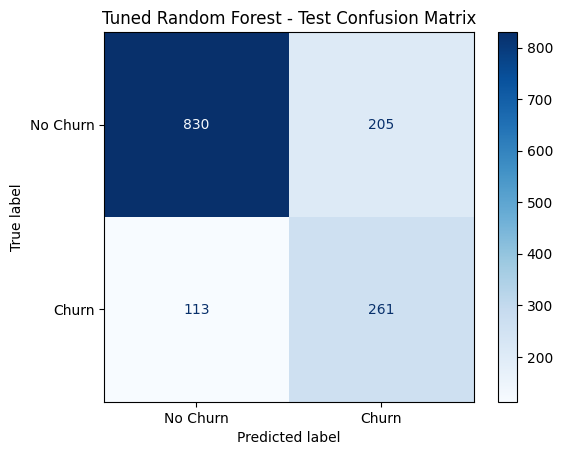

In [22]:
best_model = tuned_models['Random Forest']
best_threshold = 0.55

y_test_prob = best_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("Final Test Results")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 3))
print("Precision:", round(precision_score(
    y_test, y_test_pred, zero_division=0
), 3))
print("Recall:", round(recall_score(
    y_test, y_test_pred, zero_division=0
), 3))
print("F1 Score:", round(f1_score(
    y_test, y_test_pred, zero_division=0
), 3))
print("ROC-AUC:", round(roc_auc_score(
    y_test, y_test_prob
), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred,
    labels=[0, 1],
    target_names=['No Churn', 'Churn'],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)
plt.title('Tuned Random Forest - Test Confusion Matrix')
plt.show()


###Logistic Regression — Final Test Evaluation

Tuned Logistic Regression - Test Results
Threshold: 0.55
Accuracy: 0.756
Precision: 0.529
Recall: 0.743
F1 Score: 0.618
ROC-AUC: 0.841

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.89      0.76      0.82      1035
       Churn       0.53      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



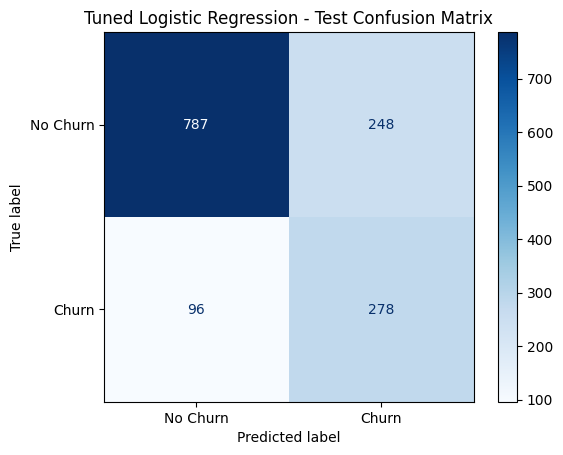

In [23]:
lr_model = tuned_models['Logistic Regression']
lr_threshold = 0.55

y_test_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_test_pred_lr = (y_test_prob_lr >= lr_threshold).astype(int)

print("Tuned Logistic Regression - Test Results")
print("Threshold:", lr_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred_lr), 3))
print("Precision:", round(precision_score(
    y_test, y_test_pred_lr, zero_division=0
), 3))
print("Recall:", round(recall_score(
    y_test, y_test_pred_lr, zero_division=0
), 3))
print("F1 Score:", round(f1_score(
    y_test, y_test_pred_lr, zero_division=0
), 3))
print("ROC-AUC:", round(roc_auc_score(
    y_test, y_test_prob_lr
), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred_lr,
    labels=[0, 1],
    target_names=['No Churn', 'Churn'],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_lr,
    labels=[0, 1],
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)
plt.title('Tuned Logistic Regression - Test Confusion Matrix')
plt.show()


## Final Model Evaluation and Comparison

### 1. Objective
The objective was to compare tuned Logistic Regression and Random Forest models for customer churn prediction using accuracy, precision, recall, F1-score, and confusion matrices.

### 2. Test Results

| Metric | Random Forest | Logistic Regression |
|---|---:|---:|
| Accuracy | 77.4% | 75.6% |
| Precision | 56.0% | 52.9% |
| Recall | 69.8% | 74.3% |
| F1-score | 62.2% | 61.9% |

### 3. Key Findings

- **Random Forest** achieved higher accuracy, precision, and F1-score.
- **Logistic Regression** achieved higher recall and missed fewer actual churners.
- Random Forest missed 113 actual churners, while Logistic Regression missed 96.
- Both models showed potential for identifying customers at risk of churn, but neither model identifies every churner correctly.

### 4. Conclusion

**Logistic Regression** was selected because it identified more actual churners than Random Forest on the test dataset, missing 96 churners compared with 113 for Random Forest.

Although Random Forest achieved slightly higher accuracy and F1-score, Logistic Regression better supports the project's priority of detecting potential churners.



### Final Model Selection: Logistic Regression

**Why Logistic Regression?**

We selected Logistic Regression because our primary business objective is to identify customers who are likely to churn and help the company take preventive retention actions.

**Test Results:**
- Accuracy: **75.6%**
- Precision: **52.9%**
- Recall: **74.3%**
- F1-score: **61.9%**

**Reason for Selection:**

Logistic Regression achieved higher recall than Random Forest, identifying more actual churners and missing fewer customers who left. Although Random Forest achieved slightly higher accuracy and F1-score, Logistic Regression better aligns with our priority of detecting potential churners.

**Conclusion:**

We will use the tuned Logistic Regression pipeline with a classification threshold of **0.55** as our selected model. Its performance will guide customer retention strategies, while recognizing that some predictions will be incorrect.


### Save the selected Logistic Regression model

In [24]:
import joblib

# Get the selected, tuned Logistic Regression pipeline
final_model = tuned_models['Logistic Regression']

# Save the model and prediction settings together
model_artifact = {
    'model': final_model,
    'threshold': 0.55,
    'target_mapping': {
        0: 'No Churn',
        1: 'Churn'
    }
}

joblib.dump(model_artifact, 'churn_model.joblib')

print("Model saved successfully!")


Model saved successfully!


### Verify the saved model

In [25]:
loaded_artifact = joblib.load('churn_model.joblib')

print("Model loaded successfully!")
print("Threshold:", loaded_artifact['threshold'])
print("Model type:", type(loaded_artifact['model']).__name__)


Model loaded successfully!
Threshold: 0.55
Model type: Pipeline
